#### EDA on Sales Data Analyze revenue patterns, customer behavior, and seasonality.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Sample_-_Superstore.csv", encoding="latin1")
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
print(df)

      Row ID        Order ID Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156 2016-11-08  11/11/2016    Second Class   
1          2  CA-2016-152156 2016-11-08  11/11/2016    Second Class   
2          3  CA-2016-138688 2016-06-12   6/16/2016    Second Class   
3          4  US-2015-108966 2015-10-11  10/18/2015  Standard Class   
4          5  US-2015-108966 2015-10-11  10/18/2015  Standard Class   
...      ...             ...        ...         ...             ...   
9989    9990  CA-2014-110422 2014-01-21   1/23/2014    Second Class   
9990    9991  CA-2017-121258 2017-02-26    3/3/2017  Standard Class   
9991    9992  CA-2017-121258 2017-02-26    3/3/2017  Standard Class   
9992    9993  CA-2017-121258 2017-02-26    3/3/2017  Standard Class   
9993    9994  CA-2017-119914 2017-05-04    5/9/2017    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520       Claire Gute   Consumer  United States      

In [2]:
print(df.head())

   Row ID        Order ID Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South  FUR

In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   str           
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [4]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64



Sales by year:
Order Date
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26
Name: Sales, dtype: float64

Sales by category:
Category
Technology         836154.03
Furniture          741999.80
Office Supplies    719047.03
Name: Sales, dtype: float64


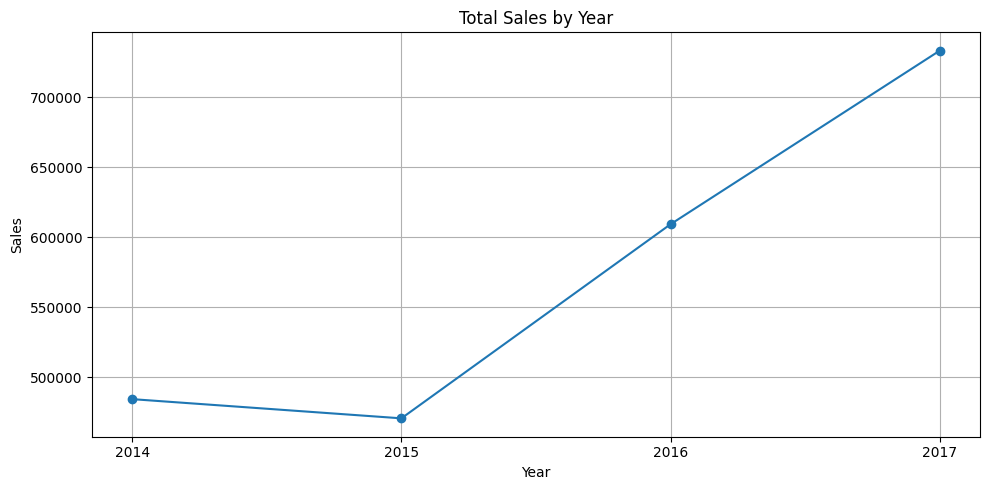

In [5]:
yearly_sales = df.groupby(df["Order Date"].dt.year)["Sales"].sum()
print("\nSales by year:")
print(yearly_sales.round(2))

category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print("\nSales by category:")
print(category_sales.round(2))

plt.figure(figsize=(10, 5))
yearly_sales.plot(kind="line", marker="o")
plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(yearly_sales.index)
plt.grid(True)
plt.tight_layout()
plt.show()

### Statement
Total sales were **$2,297,200.86** from 2014 to 2017. Yearly sales dipped slightly from $484,247.50 in 2014 to $470,532.51 in 2015 (-2.8%), then grew to $609,205.60 in 2016 (+29.5%) and $733,215.26 in 2017 (+20.4%). Technology earned the most revenue with $836,154.03, followed by Furniture ($741,999.80) and Office Supplies ($719,047.03). Overall, revenue grew strongly after 2015, and the three categories contribute almost equally.


Top customers:
Customer Name
Sean Miller           25043.05
Tamara Chand          19052.22
Raymond Buch          15117.34
Tom Ashbrook          14595.62
Adrian Barton         14473.57
Ken Lonsdale          14175.23
Sanjit Chand          14142.33
Hunter Lopez          12873.30
Sanjit Engle          12209.44
Christopher Conant    12129.07
Name: Sales, dtype: float64

Sales share by segment (%):
Segment
Consumer       50.6
Corporate      30.7
Home Office    18.7
Name: Sales, dtype: float64

Total customers: 793
Average orders per customer: 6.3


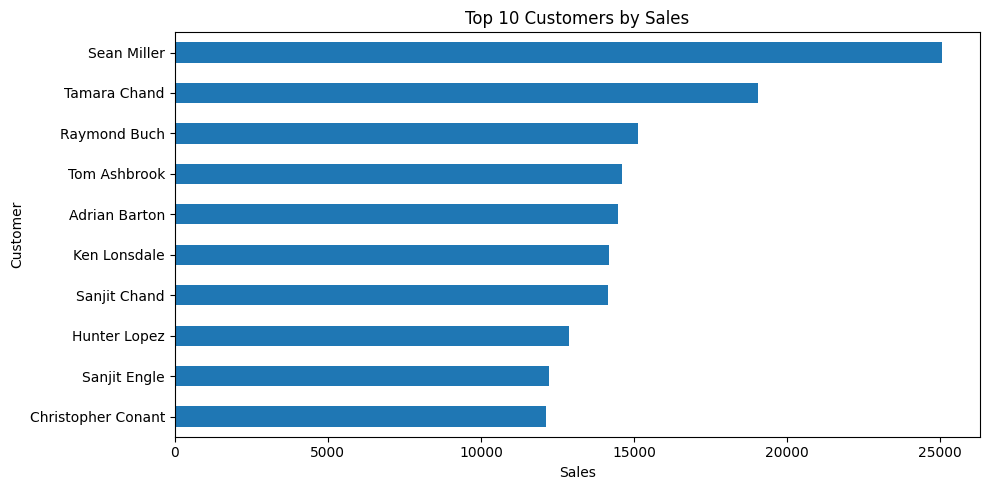

In [6]:
customer_sales = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False)
top_customers = customer_sales.head(10)
print("\nTop customers:")
print(top_customers.round(2))

print("\nSales share by segment (%):")
print((df.groupby("Segment")["Sales"].sum() / df["Sales"].sum() * 100).round(1))

orders_per_customer = df.groupby("Customer ID")["Order ID"].nunique()
print("\nTotal customers:", df["Customer ID"].nunique())
print("Average orders per customer:", round(orders_per_customer.mean(), 1))

plt.figure(figsize=(10, 5))
top_customers.sort_values().plot(kind="barh")
plt.title("Top 10 Customers by Sales")
plt.xlabel("Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

### Statement
Sean Miller is the top customer with $25,043.05 in sales, followed by Tamara Chand ($19,052.22) and Raymond Buch ($15,117.34). Christopher Conant is the lowest of the top 10 with $12,129.07. The Consumer segment brings in 50.6% of sales, followed by Corporate (30.7%) and Home Office (18.7%). The 793 customers placed about 6.3 orders each on average, so customers buy repeatedly on average.


Sales by month (all years combined):
Jan     94924.84
Feb     59751.25
Mar    205005.49
Apr    137762.13
May    155028.81
Jun    152718.68
Jul    147238.10
Aug    159044.06
Sep    307649.95
Oct    200322.98
Nov    352461.07
Dec    325293.50
Name: Sales, dtype: float64

Oct-Dec share of total sales: 38.2%


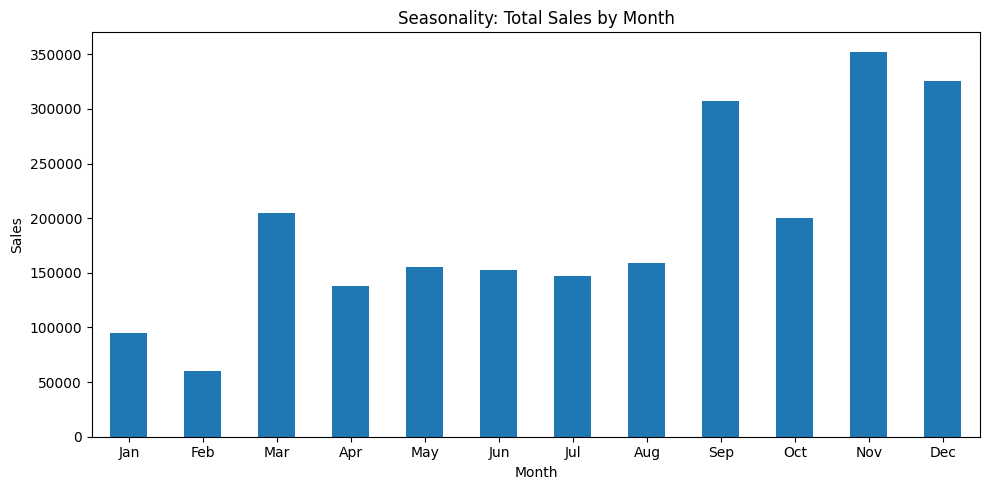

In [7]:
monthly_sales = df.groupby(df["Order Date"].dt.month)["Sales"].sum()
monthly_sales.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print("\nSales by month (all years combined):")
print(monthly_sales.round(2))

q4_share = monthly_sales[["Oct", "Nov", "Dec"]].sum() / monthly_sales.sum() * 100
print("\nOct-Dec share of total sales: " + str(round(q4_share, 1)) + "%")

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="bar")
plt.title("Seasonality: Total Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Statement
Sales are clearly seasonal. November is the highest month with $352,461.07, followed by December ($325,293.50) and September ($307,649.95). February is the lowest with $59,751.25, followed by January ($94,924.84). October to December together bring in 38.2% of all sales. Overall, sales peak in the last quarter of the year, and the start of the year is the slowest period.